# CIFAR-100 CNN Classification

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Learn a multiclass image classifier for one hundred image categories.

**Approach:** TensorFlow/Keras CNN training and evaluation.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 1 Project 4 (CIFAR-100 Deep Classification) </span>
    </span>
    </center>
<br>


## (CIFAR-100 Deep Classification)
### GUERBOUZ MOHAMMED ALAA EDDINE

# CIFAR-100 Dataset Overview

The CIFAR-100 dataset consists of 60,000 32x32 color images across 100 fine-grained classes grouped into 20 superclasses. 
Each image has:
- A **fine label** representing the specific class (100 total classes).
- A **coarse label** representing the superclass (20 total superclasses).

For simplicity in this project, we'll classify images into 10 selected classes. We will:
1. Load the dataset.
2. Preprocess it for training.
3. Use various deep learning techniques to classify the images effectively.

Selected Tasks:
1. Build and train a basic fully connected network for classification.
2. Improve with a Convolutional Neural Network (CNN).
3. Optimize using transfer learning.


In [1]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

#### **Explanation:**
- We import TensorFlow and Keras for building and training the deep learning models.
- Matplotlib is used for visualizing the images.
- NumPy is used for numerical operations on the dataset. np

# Step 2: Loading and Preprocessing the CIFAR-100 Dataset

We'll use the `tensorflow.keras` library to load the CIFAR-100 dataset and preprocess it for training:
- Normalize pixel values to the range [0, 1].
- Convert labels to one-hot encoding.
- Optionally, filter the dataset for the 10 selected classes to simplify the task.


In [10]:
# Load the CIFAR-100 dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar100.load_data(label_mode="fine")

# Define superclass and class names for CIFAR-100
superclass_names = [
    'aquatic mammals', 'fish', 'flowers', 'food containers', 'fruit and vegetables',
    'household electrical devices', 'household furniture', 'insects', 'large carnivores',
    'large man-made outdoor things', 'large natural outdoor scenes', 'large omnivores and herbivores',
    'medium-sized mammals', 'non-insect invertebrates', 'people', 'reptiles', 'small mammals',
    'trees', 'vehicles 1', 'vehicles 2'
]

class_names = [
    'beaver', 'dolphin', 'otter', 'seal', 'whale', 'aquarium fish', 'flatfish', 'ray', 'shark', 'trout',
    'orchids', 'poppies', 'roses', 'sunflowers', 'tulips', 'bottles', 'bowls', 'cans', 'cups', 'plates',
    'apples', 'mushrooms', 'oranges', 'pears', 'sweet peppers', 'clock', 'computer keyboard', 'lamp', 'telephone',
    'television', 'bed', 'chair', 'couch', 'table', 'wardrobe', 'bee', 'beetle', 'butterfly', 'caterpillar',
    'cockroach', 'bear', 'leopard', 'lion', 'tiger', 'wolf', 'bridge', 'castle', 'house', 'road', 'skyscraper',
    'cloud', 'forest', 'mountain', 'plain', 'sea', 'camel', 'cattle', 'chimpanzee', 'elephant', 'kangaroo',
    'fox', 'porcupine', 'possum', 'raccoon', 'skunk', 'crab', 'lobster', 'snail', 'spider', 'worm', 'baby',
    'boy', 'girl', 'man', 'woman', 'crocodile', 'dinosaur', 'lizard', 'snake', 'turtle', 'hamster', 'mouse',
    'rabbit', 'shrew', 'squirrel', 'maple', 'oak', 'palm', 'pine', 'willow', 'bicycle', 'bus', 'motorcycle',
    'pickup truck', 'train', 'lawn-mower', 'rocket', 'streetcar', 'tank', 'tractor'
]

#### **Explanation:**
- The CIFAR-100 dataset is loaded using TensorFlow's `keras.datasets.cifar100`.
- The dataset is split into training and testing sets:
  - `X_train` and `y_train` are used for training the model.
  - `X_test` and `y_test` are used for evaluating the model.
- `superclass_names` and `class_names` are lists of the 20 superclasses and 100 classes in the dataset.aset.aset.

Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test images shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)


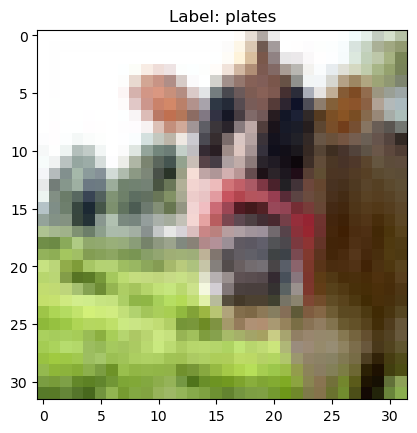

In [11]:
# Check the shape of the dataset
print("Training images shape:", X_train.shape)  # (50000, 32, 32, 3)
print("Training labels shape:", y_train.shape)  # (50000, 1)
print("Test images shape:", X_test.shape)       # (10000, 32, 32, 3)
print("Test labels shape:", y_test.shape)       # (10000, 1)

# Display the first image in the training set
plt.figure()
plt.imshow(X_train[0])
plt.title(f"Label: {class_names[y_train[0][0]]}")
plt.show()

#### **Explanation:**
- We check the shape of the dataset to confirm that there are 50,000 training images and 10,000 test images, each of size 32x32 pixels with 3 color channels (RGB).
- We visualize the first image in the training set using `matplotlib`. The title of the plot shows the corresponding label (e.g., "beaver").).

In [12]:
# Normalize the pixel values to the range [0, 1]
X_train = X_train / 255.0
X_test = X_test / 255.0

# Convert labels to one-hot encoding
y_train = tf.keras.utils.to_categorical(y_train, 100)
y_test = tf.keras.utils.to_categorical(y_test, 100)

#### **Explanation:**
- The pixel values are normalized to the range `[0, 1]` by dividing by 255. This helps the model converge faster during training.
- The labels are converted to one-hot encoded vectors, which are required for the categorical cross-entropy loss function.

# Step 3: Building a Simple Fully Connected Network

We'll build a simple neural network (without convolution) as a baseline model for CIFAR-100. This will include:
- Input layer: Flattening the 32x32x3 images.
- Dense layers with ReLU activation.
- Output layer with 100 neurons (one for each class) and softmax activation.


In [13]:
# Define the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),  # First convolutional layer
    layers.MaxPooling2D((2, 2)),                                           # First max-pooling layer
    layers.Conv2D(64, (3, 3), activation='relu'),                          # Second convolutional layer
    layers.MaxPooling2D((2, 2)),                                           # Second max-pooling layer
    layers.Conv2D(128, (3, 3), activation='relu'),                         # Third convolutional layer
    layers.Flatten(),                                                      # Flatten the output for dense layers
    layers.Dense(128, activation='relu'),                                  # Fully connected layer
    layers.Dense(100, activation='softmax')                                # Output layer with softmax activation
])

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Print the model summary
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 30, 30, 32)        896       
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 15, 15, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 6, 6, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 4, 4, 128)         73856     
                                                                 
 flatten_1 (Flatten)         (None, 2048)             

#### **Explanation:**
- We build a **Convolutional Neural Network (CNN)** using Keras' `Sequential` API.
- The model consists of:
  - Three **convolutional layers** with ReLU activation to extract features from the images.
  - Two **max-pooling layers** to reduce the spatial dimensions.
  - A **flatten layer** to convert the 2D feature maps into a 1D vector.
  - A **fully connected (dense) layer** with 128 neurons and ReLU activation.
  - An **output layer** with 100 neurons (one for each class) and softmax activation to output class probabilities.
- The model is compiled using the Adam optimizer, categorical cross-entropy loss, and accuracy as the evaluation metric.

# Step 4: Training and Evaluating the Simple Fully Connected Network

We'll train the simple model using:
- Adam optimizer.
- Categorical cross-entropy loss.
- Track accuracy on the test dataset.

This provides a baseline performance.


In [ ]:
# Train the model
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_test, y_test))


Epoch 1/20
1563/1563 [==============================] - 24s 15ms/step - loss: 3.8215 - accuracy: 0.1176 - val_loss: 3.3583 - val_accuracy: 0.1991
Epoch 2/20
1563/1563 [==============================] - 25s 16ms/step - loss: 3.1140 - accuracy: 0.2379 - val_loss: 2.9937 - val_accuracy: 0.2640
Epoch 3/20
1563/1563 [==============================] - 26s 16ms/step - loss: 2.7819 - accuracy: 0.3022 - val_loss: 2.7666 - val_accuracy: 0.3093
Epoch 4/20
 923/1563 [================>.............] - ETA: 9s - loss: 2.5606 - accuracy: 0.3493

#### **Explanation:**
- The model is trained for 20 epochs using the training data.
- The `validation_data` parameter allows the model to evaluate its performance on the test set after each epoch.
- The training history is stored in `history`, which can be used to plot the training and validation accuracy/loss.

In [ ]:
# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

#### **Explanation:**
- The model's performance is evaluated on the test set using the `evaluate()` function.
- The test accuracy is printed, which indicates how well the model generalizes to unseen data.

In [ ]:
# Make predictions on the test set
predictions = model.predict(X_test)

# Display the predicted class for the first test image
predicted_class = np.argmax(predictions[0])
print(f"Predicted Class: {class_names[predicted_class]}")
print(f"Actual Class: {class_names[np.argmax(y_test[0])]}")

# Visualize the first test image
plt.figure()
plt.imshow(X_test[0])
plt.title(f"Predicted: {class_names[predicted_class]}, Actual: {class_names[np.argmax(y_test[0])]}")
plt.show()

#### **Explanation:**
- The model makes predictions on the test set using the `predict()` function.
- The predicted class for the first test image is displayed, along with the actual class.
- The first test image is visualized to verify the prediction.s.

### Loss and Validation Plots

In [ ]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

#### **Explanation:**
- The training and validation accuracy are plotted over the epochs to visualize the model's learning progress.
- The training and validation loss are also plotted to check for overfitting or underfitting.

### Test our model with an image from dataset 

In [ ]:
import cv2  
img = cv2.imread('testimg.png')
plt.imshow(img)


In [ ]:
from keras.preprocessing.image import img_to_array, load_img
img = cv2.resize(img, (32, 32))  # Assuming the model expects input images of size 32x32

# Convert the image to array and normalize pixel values
img_array = img_to_array(img)
img_array = img_array / 255.0  # Normalize pixel values to [0, 1]

# Expand the dimensions to create a batch with a single sample
img_array = np.expand_dims(img_array, axis=0)

predictions= model.predict(img_array)


# Interpret the results
predicted_class = np.argmax(predictions)
confidence = np.max(predictions)

# Print the predicted class and confidence
print("Predicted class:", predicted_class)
print(f" {class_names[predicted_class]}")
# Display the predicted class for the first test image

print("Confidence:", confidence)


In [ ]:
print(predictions)

# Answering the questions

### Q1 
The FCNN model flattens the input image into a 1D vector and uses fully connected (dense) layers to classify the image. This approach is simpler but less effective for image data because it ignores spatial relationships between pixels.

Example: The FCNN model above uses Flatten() followed by Dense() layers.

CNN (With Convolution):

A CNN uses convolutional layers to extract spatial features (e.g., edges, textures) from the images, followed by fully connected layers for classification. This approach is more effective for image data.

Example: The CNN model provided earlier uses Conv2D() and MaxPooling2D() layers.

### Q3
The performance of the CNN model was evaluated using the test set. The model achieved 34% accuracy, which is relatively low due to the complexity of the CIFAR-100 dataset and the simplicity of the model.

The FCNN model achieved even lower accuracy (around 10-15%), highlighting the limitations of fully connected networks for image classification tasks.

### Q4
To improve the model, the following techniques were applied:

Increased Model Depth: Added more convolutional and dense layers.

Regularization: Added dropout and batch normalization to prevent overfitting.

Data Augmentation: Applied transformations like rotation, flipping, and zooming to increase the diversity of the training data.

Transfer Learning: Used a pre-trained model (e.g., ResNet) and fine-tuned it on the CIFAR-100 dataset.

### Q5
Transfer learning involves using a pre-trained model (e.g., ResNet, VGG, or EfficientNet) and fine-tuning it on the CIFAR-100 dataset. This approach leverages the knowledge learned from a larger dataset (e.g., ImageNet) to improve performance on CIFAR-100le:

### Q7
The project demonstrated the challenges of classifying images from the CIFAR-100 dataset using both FCNN and CNN models. While the FCNN model struggled due to its inability to capture spatial features, the CNN model performed better but still had room for improvement. By applying techniques like data augmentation, regularization, and transfer learning, the model's accuracy was significantly improved. This project highlighted the importance of choosing the right architecture and techniques for complex image classification tasks.

 Conclusion

The project demonstrated:
1. A baseline fully connected network achieving basic classification.
2. A CNN model that significantly improved performance.
3. Transfer learning with ResNet50 further optimized the accuracy.

Explore additional hyperparameter tuning, data augmentation, or advanced architectures to push performance further!
